# Phase 2 - Geological And Domain EDA

This notebook builds the domain picture needed before stronger models: TVT smoothness, GR/typewell alignment, spatial trajectory behavior, train/test similarity, and train-only formation context. Outputs are saved under `artifacts/tables/`, `artifacts/figures/`, and `artifacts/reports/`.

## 1. Setup

Load paths, packages, and well ids. This pass intentionally works from raw CSVs so findings remain tied to the immutable Kaggle data.

In [1]:
"Imports, paths, constants, and output locations."

import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    for parent in ROOT.parents:
        if (parent / "src").is_dir():
            ROOT = parent
            break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.io.loaders import discover_wells, load_horizontal_well, load_sample_submission, load_typewell
from src.utils.paths import get_artifacts_dir, get_data_dir, get_sample_submission_path
from src.utils.run_bundle import RunBundle
from src.utils.seeds import set_global_seeds

set_global_seeds(42)
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("default")

RUN_DATE = date.today().isoformat()
TRAIN_ONLY_FORMATIONS = ["ANCC", "ASTNU", "ASTNL", "EGFDU", "EGFDL", "BUDA"]
SAMPLE_WELL_COUNT = 18
TYPEWELL_SAMPLE_PER_WELL = 500

train_dir = get_data_dir("train")
test_dir = get_data_dir("test")
sample_path = get_sample_submission_path()
tables_dir = get_artifacts_dir("tables")
figures_dir = get_artifacts_dir("figures")
reports_dir = get_artifacts_dir("reports")
for directory in [tables_dir, figures_dir, reports_dir]:
    directory.mkdir(parents=True, exist_ok=True)

train_wells = discover_wells(train_dir)
test_wells = discover_wells(test_dir)
sample_submission = load_sample_submission(sample_path)

print("train wells:", len(train_wells))
print("test wells:", len(test_wells))
print("sample rows:", len(sample_submission))
print("tables_dir:", tables_dir)
print("figures_dir:", figures_dir)

15:04:43 | INFO     | src.io.loaders | Discovered 773 wells in C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\data\raw\train


15:04:43 | INFO     | src.io.loaders | Discovered 3 wells in C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\data\raw\test


train wells: 773
test wells: 3
sample rows: 14151
tables_dir: C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables
figures_dir: C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\figures


## 2. Summary Helpers

Create per-well domain summaries: zone geometry, GR missingness, trajectory footprint, TVT smoothness, endpoint behavior, and typewell/geology context.

In [2]:
"Well-level summary, formation, typewell, and alignment helper functions."


def q(series, prob):
    clean = pd.Series(series).dropna()
    if clean.empty:
        return np.nan
    return float(clean.quantile(prob))


def finite_corr(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    if mask.sum() < 5:
        return np.nan
    return float(np.corrcoef(a[mask], b[mask])[0, 1])


def horizontal_distance(df):
    dx = df["X"].astype(float).diff().fillna(0.0)
    dy = df["Y"].astype(float).diff().fillna(0.0)
    return np.sqrt(dx * dx + dy * dy).cumsum()


def summarize_horizontal(well, split):
    directory = train_dir if split == "train" else test_dir
    df = load_horizontal_well(directory / f"{well}__horizontal_well.csv")
    has_tvt = "TVT" in df.columns
    known_mask = df["TVT_input"].notna()
    eval_mask = df["TVT_input"].isna()
    dist = horizontal_distance(df)
    known_idx = np.flatnonzero(known_mask.to_numpy())
    eval_idx = np.flatnonzero(eval_mask.to_numpy())
    known_tvt = df.loc[known_mask, "TVT_input"].astype(float)
    true_tvt = df["TVT"].astype(float) if has_tvt else pd.Series(index=df.index, dtype=float)
    row = {
        "well": well,
        "split": split,
        "n_rows": int(len(df)),
        "known_rows": int(known_mask.sum()),
        "eval_rows": int(eval_mask.sum()),
        "eval_frac": float(eval_mask.mean()),
        "md_min": float(df["MD"].min()),
        "md_max": float(df["MD"].max()),
        "md_range": float(df["MD"].max() - df["MD"].min()),
        "x_range": float(df["X"].max() - df["X"].min()),
        "y_range": float(df["Y"].max() - df["Y"].min()),
        "z_range": float(df["Z"].max() - df["Z"].min()),
        "horizontal_length": float(dist.iloc[-1]) if len(dist) else np.nan,
        "gr_missing_frac": float(df["GR"].isna().mean()),
        "gr_known_missing_frac": float(df.loc[known_mask, "GR"].isna().mean()) if known_mask.any() else np.nan,
        "gr_eval_missing_frac": float(df.loc[eval_mask, "GR"].isna().mean()) if eval_mask.any() else np.nan,
        "gr_mean": float(df["GR"].mean(skipna=True)),
        "gr_std": float(df["GR"].std(skipna=True)),
        "gr_p10": q(df["GR"], 0.10),
        "gr_p50": q(df["GR"], 0.50),
        "gr_p90": q(df["GR"], 0.90),
    }
    if len(known_idx):
        last_known_pos = int(known_idx[-1])
        row.update({
            "last_known_row": last_known_pos,
            "last_known_md": float(df.iloc[last_known_pos]["MD"]),
            "last_known_tvt_input": float(df.iloc[last_known_pos]["TVT_input"]),
            "last_known_gr": float(df.iloc[last_known_pos]["GR"]) if pd.notna(df.iloc[last_known_pos]["GR"]) else np.nan,
            "known_tvt_min": float(known_tvt.min()),
            "known_tvt_max": float(known_tvt.max()),
            "known_tvt_range": float(known_tvt.max() - known_tvt.min()),
            "known_tvt_slope_median": float((known_tvt.diff() / df.loc[known_mask, "MD"].diff()).replace([np.inf, -np.inf], np.nan).median()),
            "known_tvt_slope_last_50": float((known_tvt.tail(50).diff() / df.loc[known_mask, "MD"].tail(50).diff()).replace([np.inf, -np.inf], np.nan).median()),
        })
    if len(eval_idx):
        first_eval_pos = int(eval_idx[0])
        row.update({
            "first_eval_row": first_eval_pos,
            "first_eval_md": float(df.iloc[first_eval_pos]["MD"]),
            "eval_md_min": float(df.loc[eval_mask, "MD"].min()),
            "eval_md_max": float(df.loc[eval_mask, "MD"].max()),
            "eval_md_range": float(df.loc[eval_mask, "MD"].max() - df.loc[eval_mask, "MD"].min()),
            "known_to_eval_md_gap": float(df.iloc[first_eval_pos]["MD"] - row.get("last_known_md", np.nan)),
        })
    if has_tvt:
        eval_tvt = true_tvt.loc[eval_mask]
        row.update({
            "eval_tvt_min": float(eval_tvt.min()) if len(eval_tvt) else np.nan,
            "eval_tvt_max": float(eval_tvt.max()) if len(eval_tvt) else np.nan,
            "eval_tvt_range": float(eval_tvt.max() - eval_tvt.min()) if len(eval_tvt) else np.nan,
            "eval_tvt_delta_from_last_known": float(eval_tvt.iloc[-1] - row.get("last_known_tvt_input", np.nan)) if len(eval_tvt) else np.nan,
            "tvt_md_corr_known": finite_corr(df.loc[known_mask, "MD"], true_tvt.loc[known_mask]),
            "tvt_z_corr_known": finite_corr(df.loc[known_mask, "Z"], true_tvt.loc[known_mask]),
            "tvt_md_corr_eval": finite_corr(df.loc[eval_mask, "MD"], true_tvt.loc[eval_mask]),
        })
    return row


def summarize_typewell(well, split):
    directory = train_dir if split == "train" else test_dir
    path = directory / f"{well}__typewell.csv"
    if not path.exists():
        return {"well": well, "split": split, "typewell_rows": 0}
    tw = load_typewell(path)
    labels = tw["Geology"].astype(str) if "Geology" in tw.columns else pd.Series(dtype=str)
    return {
        "well": well,
        "split": split,
        "typewell_rows": int(len(tw)),
        "typewell_tvt_min": float(tw["TVT"].min()) if len(tw) else np.nan,
        "typewell_tvt_max": float(tw["TVT"].max()) if len(tw) else np.nan,
        "typewell_gr_mean": float(tw["GR"].mean(skipna=True)) if len(tw) else np.nan,
        "typewell_gr_std": float(tw["GR"].std(skipna=True)) if len(tw) else np.nan,
        "typewell_geology_count": int(labels.nunique()) if len(labels) else 0,
        "typewell_geology_labels": ",".join(sorted(labels.dropna().unique().tolist())) if len(labels) else "",
    }


def formation_summary(well):
    df = load_horizontal_well(train_dir / f"{well}__horizontal_well.csv")
    row = {"well": well}
    for col in TRAIN_ONLY_FORMATIONS:
        if col in df.columns:
            row[f"{col}_missing_frac"] = float(df[col].isna().mean())
            row[f"{col}_median"] = float(df[col].median(skipna=True))
        else:
            row[f"{col}_missing_frac"] = np.nan
            row[f"{col}_median"] = np.nan
    medians = [row[f"{col}_median"] for col in TRAIN_ONLY_FORMATIONS if np.isfinite(row[f"{col}_median"])]
    row["formation_median_order_is_monotone"] = bool(np.all(np.diff(medians) >= 0)) if len(medians) > 1 else np.nan
    return row


def typewell_alignment(well):
    df = load_horizontal_well(train_dir / f"{well}__horizontal_well.csv")
    tw_path = train_dir / f"{well}__typewell.csv"
    if not tw_path.exists():
        return {"well": well, "alignment_rows": 0, "horiz_typewell_gr_corr": np.nan}
    tw = load_typewell(tw_path).dropna(subset=["TVT", "GR"]).sort_values("TVT")
    known = df[df["TVT_input"].notna() & df["GR"].notna()].copy()
    if len(known) > TYPEWELL_SAMPLE_PER_WELL:
        known = known.iloc[np.linspace(0, len(known) - 1, TYPEWELL_SAMPLE_PER_WELL).astype(int)]
    if len(known) < 5 or len(tw) < 5:
        return {"well": well, "alignment_rows": int(len(known)), "horiz_typewell_gr_corr": np.nan}
    interp = np.interp(known["TVT_input"].astype(float), tw["TVT"].astype(float), tw["GR"].astype(float))
    return {
        "well": well,
        "alignment_rows": int(len(known)),
        "horiz_typewell_gr_corr": finite_corr(known["GR"], interp),
        "horiz_typewell_gr_absdiff_median": float(np.median(np.abs(known["GR"].to_numpy(dtype=float) - interp))),
    }

## 3. Build Well-Level Tables

Summarize train and test wells without using train-only columns as model features. These tables are the backbone for later feature and validation decisions.

In [3]:
"Build train/test well summaries, typewell summaries, formation tables, and alignment tables."

train_summary = pd.DataFrame([summarize_horizontal(well, "train") for well in train_wells])
test_summary = pd.DataFrame([summarize_horizontal(well, "test") for well in test_wells])
typewell_summary = pd.DataFrame(
    [summarize_typewell(well, "train") for well in train_wells]
    + [summarize_typewell(well, "test") for well in test_wells]
)
formation_df = pd.DataFrame([formation_summary(well) for well in train_wells])
alignment_df = pd.DataFrame([typewell_alignment(well) for well in train_wells])

train_summary_path = tables_dir / f"eda__phase2_train_well_summary__{RUN_DATE}.csv"
test_summary_path = tables_dir / f"eda__phase2_test_well_summary__{RUN_DATE}.csv"
typewell_summary_path = tables_dir / f"eda__phase2_typewell_summary__{RUN_DATE}.csv"
formation_path = tables_dir / f"eda__phase2_formation_summary__{RUN_DATE}.csv"
alignment_path = tables_dir / f"eda__phase2_typewell_alignment__{RUN_DATE}.csv"

train_summary.to_csv(train_summary_path, index=False)
test_summary.to_csv(test_summary_path, index=False)
typewell_summary.to_csv(typewell_summary_path, index=False)
formation_df.to_csv(formation_path, index=False)
alignment_df.to_csv(alignment_path, index=False)

print("train summary:", train_summary.shape, train_summary_path)
print("test summary:", test_summary.shape, test_summary_path)
print("typewell summary:", typewell_summary.shape, typewell_summary_path)
print("formation summary:", formation_df.shape, formation_path)
print("alignment summary:", alignment_df.shape, alignment_path)
train_summary.describe(include="all").transpose().head(20)

train summary: (773, 43) C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_train_well_summary__2026-06-21.csv
test summary: (3, 36) C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_test_well_summary__2026-06-21.csv
typewell summary: (776, 9) C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_typewell_summary__2026-06-21.csv
formation summary: (773, 14) C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_formation_summary__2026-06-21.csv
alignment summary: (773, 4) C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_typewell_alignment__2026-06-21.csv


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
well,773,773,000d7d20,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,773,1,train,773,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_rows,773.0,NaN,NaN,NaN,6587.652005,1311.463547,2058.0,5706.0,6576.0,7388.0,12141.0
known_rows,773.0,NaN,NaN,NaN,1692.452781,217.343826,851.0,1546.0,1703.0,1839.0,2392.0
eval_rows,773.0,NaN,NaN,NaN,4895.199224,1301.178409,407.0,4044.0,4840.0,5694.0,10052.0
eval_frac,773.0,NaN,NaN,NaN,0.733161,0.063776,0.197765,0.700344,0.739991,0.775462,0.875165
md_min,773.0,NaN,NaN,NaN,10900.468305,645.754853,9335.0,10403.0,10746.0,11434.0,12573.0
md_max,773.0,NaN,NaN,NaN,17487.12031,1428.482449,12854.0,16511.0,17522.0,18378.0,22964.0
md_range,773.0,NaN,NaN,NaN,6586.652005,1311.463547,2057.0,5705.0,6575.0,7387.0,12140.0
x_range,773.0,NaN,NaN,NaN,2937.61727,1588.706165,20.35,1896.28,3132.49,4129.6,7540.56


## 4. Evaluation-Zone And TVT Geometry

The competition asks us to extrapolate from a known-zone prefix into a trailing evaluation zone. This section measures how large that extrapolation is and how smooth TVT looks within train wells.

In [4]:
"Summarize eval-zone fractions, TVT smoothness, and endpoint extrapolation behavior."

key_zone_cols = [
    "n_rows", "known_rows", "eval_rows", "eval_frac", "md_range", "eval_md_range",
    "known_tvt_range", "eval_tvt_range", "eval_tvt_delta_from_last_known",
    "known_tvt_slope_median", "known_tvt_slope_last_50", "tvt_md_corr_known", "tvt_md_corr_eval",
]
zone_summary = train_summary[key_zone_cols].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).transpose()
zone_summary_path = tables_dir / f"eda__phase2_eval_zone_tvt_summary__{RUN_DATE}.csv"
zone_summary.to_csv(zone_summary_path)
print("zone summary:", zone_summary_path)
zone_summary

zone summary: C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_eval_zone_tvt_summary__2026-06-21.csv


,count,mean,std,min,10%,25%,50%,75%,90%,max
n_rows,773.0,6587.652005,1311.463547,2058.000000,4993.000000,5706.000000,6576.000000,7388.000000,8056.400000,12141.000000
known_rows,773.0,1692.452781,217.343826,851.000000,1422.600000,1546.000000,1703.000000,1839.000000,1945.000000,2392.000000
eval_rows,773.0,4895.199224,1301.178409,407.000000,3263.000000,4044.000000,4840.000000,5694.000000,6348.600000,10052.000000
eval_frac,773.0,0.733161,0.063776,0.197765,0.653590,0.700344,0.739991,0.775462,0.803304,0.875165
md_range,773.0,6586.652005,1311.463547,2057.000000,4992.000000,5705.000000,6575.000000,7387.000000,8055.400000,12140.000000
eval_md_range,773.0,4894.199224,1301.178409,406.000000,3262.000000,4043.000000,4839.000000,5693.000000,6347.600000,10051.000000
known_tvt_range,773.0,722.395783,174.963105,135.630000,489.628000,579.250000,747.740000,843.010000,925.708000,1185.060000
eval_tvt_range,773.0,29.407374,14.792170,3.620000,15.080000,19.590000,26.370000,35.430000,46.816000,121.840000
eval_tvt_delta_from_last_known,773.0,0.984605,20.583950,-103.780000,-21.514000,-9.500000,1.400000,12.000000,22.690000,89.740000
known_tvt_slope_median,773.0,0.318525,0.148675,-0.010000,0.120000,0.210000,0.320000,0.420000,0.510000,0.860000


## 5. GR And Typewell Signal

Gamma Ray is available in both train and test, but it has missingness and geological context. Here we compare train/test GR distributions and test whether horizontal GR roughly aligns with typewell GR at known TVT positions.

In [5]:
"Compare train/test GR distributions and typewell alignment quality."

alignment_summary = alignment_df["horiz_typewell_gr_corr"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
missing_summary = pd.DataFrame({
    "train": train_summary[["gr_missing_frac", "gr_known_missing_frac", "gr_eval_missing_frac"]].mean(),
    "test": test_summary[["gr_missing_frac", "gr_known_missing_frac", "gr_eval_missing_frac"]].mean(),
})
print("typewell alignment corr summary")
print(alignment_summary)
print("GR missingness summary")
print(missing_summary)
missing_summary

typewell alignment corr summary
count    773.000000
mean       0.801877
std        0.094695
min        0.191315
10%        0.683603
25%        0.758305
50%        0.812477
75%        0.865657
90%        0.904133
max        0.972275
Name: horiz_typewell_gr_corr, dtype: float64
GR missingness summary
                          train      test
gr_missing_frac        0.293854  0.214637
gr_known_missing_frac  0.236005  0.152470
gr_eval_missing_frac   0.314863  0.236313


,train,test
gr_missing_frac,0.293854,0.214637
gr_known_missing_frac,0.236005,0.152470
gr_eval_missing_frac,0.314863,0.236313


## 6. Train/Test Similarity

The public test split has only three wells locally, so each test well matters. Compare each test well to train wells using geometry, GR, and eval-zone descriptors.

In [6]:
"Compute nearest train wells to each test well in summary-feature space."

similarity_features = [
    "n_rows", "known_rows", "eval_rows", "eval_frac", "md_range", "eval_md_range",
    "x_range", "y_range", "z_range", "horizontal_length", "gr_missing_frac", "gr_mean", "gr_std", "gr_p10", "gr_p50", "gr_p90",
]
train_sim = train_summary[["well"] + similarity_features].copy()
test_sim = test_summary[["well"] + similarity_features].copy()
feature_medians = train_sim[similarity_features].median(numeric_only=True)
feature_scales = train_sim[similarity_features].std(numeric_only=True).replace(0, 1)
train_scaled = (train_sim[similarity_features].fillna(feature_medians) - feature_medians) / feature_scales
test_scaled = (test_sim[similarity_features].fillna(feature_medians) - feature_medians) / feature_scales

rows = []
for test_idx, test_well in enumerate(test_sim["well"]):
    distances = np.sqrt(((train_scaled - test_scaled.iloc[test_idx]) ** 2).sum(axis=1))
    nearest = distances.sort_values().head(10)
    for rank, train_idx in enumerate(nearest.index, start=1):
        rows.append({
            "test_well": test_well,
            "nearest_rank": rank,
            "train_well": train_sim.loc[train_idx, "well"],
            "summary_distance": float(nearest.loc[train_idx]),
            "train_eval_frac": float(train_summary.loc[train_idx, "eval_frac"]),
            "train_gr_mean": float(train_summary.loc[train_idx, "gr_mean"]),
            "train_eval_tvt_delta": float(train_summary.loc[train_idx, "eval_tvt_delta_from_last_known"]),
        })

test_similarity = pd.DataFrame(rows)
test_similarity_path = tables_dir / f"eda__phase2_test_train_similarity__{RUN_DATE}.csv"
test_similarity.to_csv(test_similarity_path, index=False)
print("test similarity:", test_similarity_path)
test_similarity.head(15)

test similarity: C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_test_train_similarity__2026-06-21.csv


,test_well,nearest_rank,train_well,summary_distance,train_eval_frac,train_gr_mean,train_eval_tvt_delta
0,000d7d20,1,000d7d20,0.000000,0.726790,94.436961,-10.06
1,000d7d20,2,46dfcfca,1.284452,0.732778,88.924662,43.34
2,000d7d20,3,46a7190b,1.381562,0.746546,90.431645,15.45
3,000d7d20,4,3a824aa7,1.510261,0.739873,96.569679,3.40
4,000d7d20,5,7bb17b96,1.513066,0.740699,90.806654,13.15
5,000d7d20,6,add9c322,1.525833,0.712448,87.472828,-7.90
6,000d7d20,7,699ea575,1.828082,0.752649,87.014418,8.82
7,000d7d20,8,4936af16,1.946958,0.717935,87.203405,2.43
8,000d7d20,9,5cb483ac,1.978828,0.739915,91.247241,6.80
9,000d7d20,10,4c3168cf,1.989979,0.727303,90.552574,7.16


## 7. Visual Diagnostics

Save figures that show the main geological/domain signals: eval-zone size, GR distribution, TVT smoothness, endpoint extrapolation, typewell alignment, XY footprint, and test/train similarity.

saved figures:
eval_fraction C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\figures\eda__phase2_eval_fraction__2026-06-21.png
gr_distribution C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\figures\eda__phase2_gr_distribution__2026-06-21.png
tvt_md_samples C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\figures\eda__phase2_tvt_md_samples__2026-06-21.png
boundary_extrapolation C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\figures\eda__phase2_boundary_extrapolation__2026-06-21.png
typewell_alignment C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\figures\eda__phase2_typewell_alignment__2026-06-21.png
xy_footprint C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\figures\eda__phase2_xy_footprint__2026-06-21.png
test_similarity C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Model

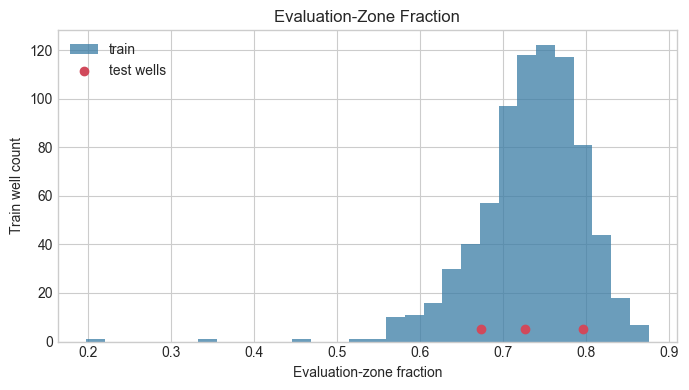

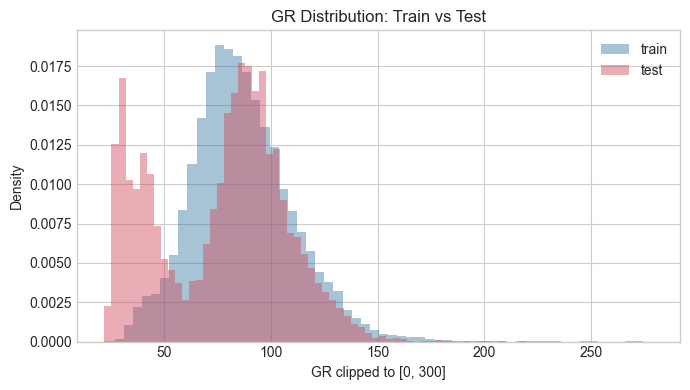

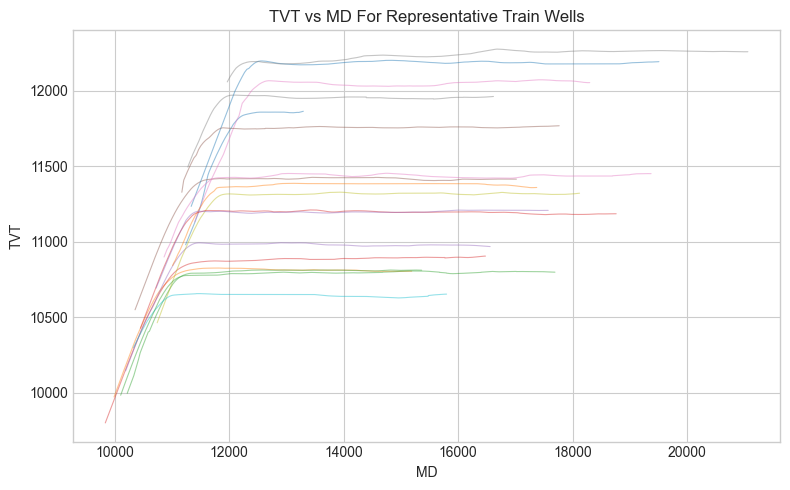

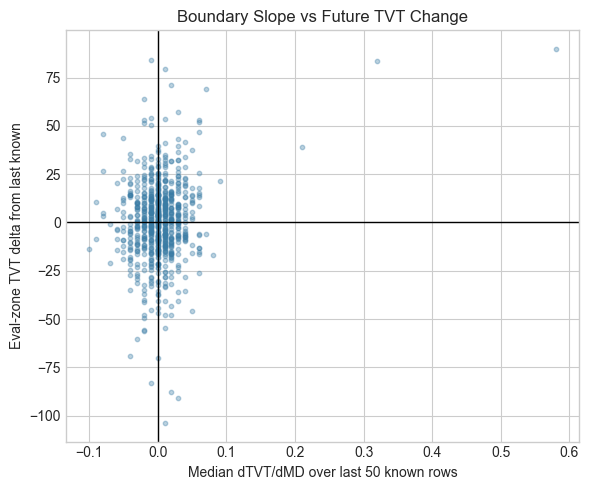

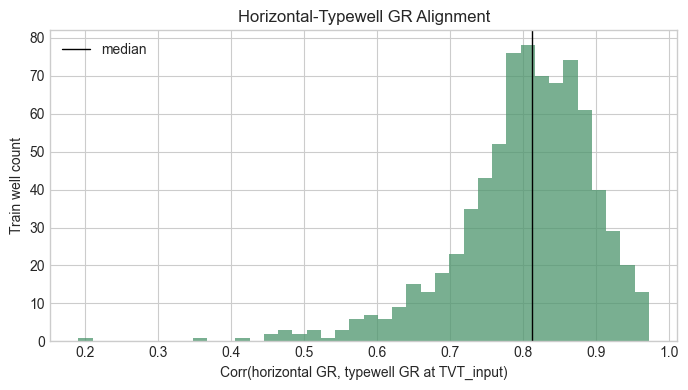

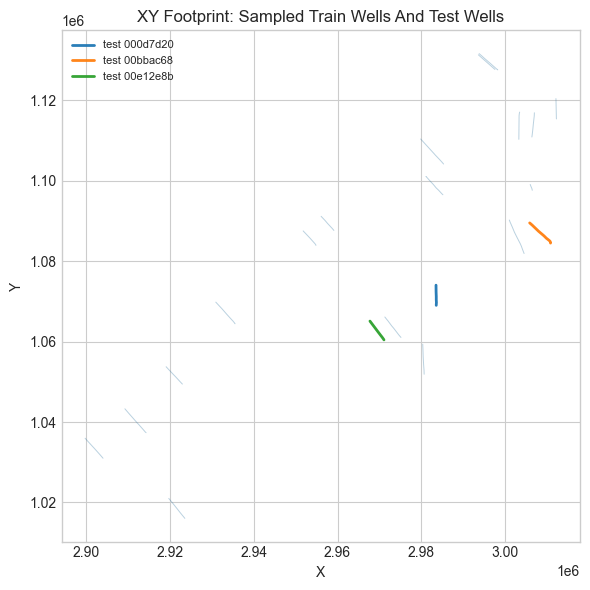

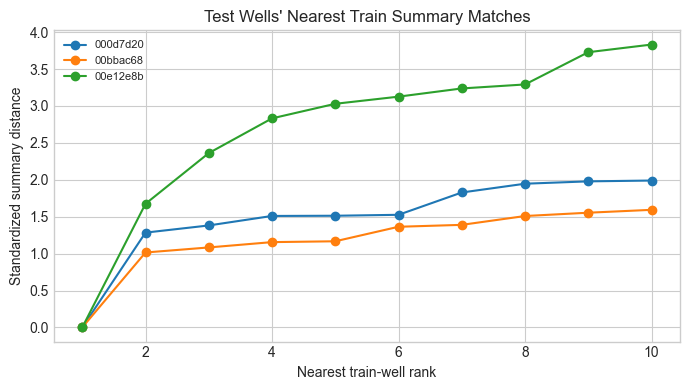

In [7]:
"Create and save Phase 2 diagnostic figures."

sample_wells = train_summary.sort_values("eval_frac").iloc[np.linspace(0, len(train_summary) - 1, SAMPLE_WELL_COUNT).astype(int)]["well"].tolist()

fig_eval, ax_eval = plt.subplots(figsize=(7, 4))
ax_eval.hist(train_summary["eval_frac"], bins=30, alpha=0.75, label="train", color="#3a7ca5")
ax_eval.scatter(test_summary["eval_frac"], np.full(len(test_summary), ax_eval.get_ylim()[1] * 0.04), color="#d1495b", label="test wells", zorder=3)
ax_eval.set_xlabel("Evaluation-zone fraction")
ax_eval.set_ylabel("Train well count")
ax_eval.set_title("Evaluation-Zone Fraction")
ax_eval.legend()
fig_eval.tight_layout()

fig_gr, ax_gr = plt.subplots(figsize=(7, 4))
train_gr_sample = []
for well in train_wells[::max(1, len(train_wells) // 120)]:
    df = load_horizontal_well(train_dir / f"{well}__horizontal_well.csv")
    non_missing = df["GR"].dropna()
    train_gr_sample.append(non_missing.sample(min(500, len(non_missing)), random_state=42) if len(non_missing) else pd.Series(dtype=float))
test_gr_sample = []
for well in test_wells:
    df = load_horizontal_well(test_dir / f"{well}__horizontal_well.csv")
    test_gr_sample.append(df["GR"].dropna())
train_gr = pd.concat(train_gr_sample, ignore_index=True)
test_gr = pd.concat(test_gr_sample, ignore_index=True)
ax_gr.hist(train_gr.clip(0, 300), bins=60, density=True, alpha=0.45, label="train", color="#3a7ca5")
ax_gr.hist(test_gr.clip(0, 300), bins=60, density=True, alpha=0.45, label="test", color="#d1495b")
ax_gr.set_xlabel("GR clipped to [0, 300]")
ax_gr.set_ylabel("Density")
ax_gr.set_title("GR Distribution: Train vs Test")
ax_gr.legend()
fig_gr.tight_layout()

fig_tvt, ax_tvt = plt.subplots(figsize=(8, 5))
for well in sample_wells:
    df = load_horizontal_well(train_dir / f"{well}__horizontal_well.csv")
    ax_tvt.plot(df["MD"], df["TVT"], linewidth=0.8, alpha=0.45)
ax_tvt.set_xlabel("MD")
ax_tvt.set_ylabel("TVT")
ax_tvt.set_title("TVT vs MD For Representative Train Wells")
fig_tvt.tight_layout()

fig_boundary, ax_boundary = plt.subplots(figsize=(6, 5))
ax_boundary.scatter(train_summary["known_tvt_slope_last_50"], train_summary["eval_tvt_delta_from_last_known"], s=10, alpha=0.35, color="#3a7ca5")
ax_boundary.axhline(0, color="black", linewidth=1)
ax_boundary.axvline(0, color="black", linewidth=1)
ax_boundary.set_xlabel("Median dTVT/dMD over last 50 known rows")
ax_boundary.set_ylabel("Eval-zone TVT delta from last known")
ax_boundary.set_title("Boundary Slope vs Future TVT Change")
fig_boundary.tight_layout()

fig_align, ax_align = plt.subplots(figsize=(7, 4))
ax_align.hist(alignment_df["horiz_typewell_gr_corr"].dropna(), bins=40, alpha=0.75, color="#4c956c")
ax_align.axvline(alignment_df["horiz_typewell_gr_corr"].median(skipna=True), color="black", linewidth=1, label="median")
ax_align.set_xlabel("Corr(horizontal GR, typewell GR at TVT_input)")
ax_align.set_ylabel("Train well count")
ax_align.set_title("Horizontal-Typewell GR Alignment")
ax_align.legend()
fig_align.tight_layout()

fig_xy, ax_xy = plt.subplots(figsize=(6, 6))
for well in sample_wells:
    df = load_horizontal_well(train_dir / f"{well}__horizontal_well.csv")
    ax_xy.plot(df["X"], df["Y"], linewidth=0.7, alpha=0.35, color="#3a7ca5")
for well in test_wells:
    df = load_horizontal_well(test_dir / f"{well}__horizontal_well.csv")
    ax_xy.plot(df["X"], df["Y"], linewidth=2.0, alpha=0.95, label=f"test {well}")
ax_xy.set_xlabel("X")
ax_xy.set_ylabel("Y")
ax_xy.set_title("XY Footprint: Sampled Train Wells And Test Wells")
ax_xy.legend(fontsize=8)
fig_xy.tight_layout()

fig_sim, ax_sim = plt.subplots(figsize=(7, 4))
for test_well, group in test_similarity.groupby("test_well"):
    ax_sim.plot(group["nearest_rank"], group["summary_distance"], marker="o", label=test_well)
ax_sim.set_xlabel("Nearest train-well rank")
ax_sim.set_ylabel("Standardized summary distance")
ax_sim.set_title("Test Wells' Nearest Train Summary Matches")
ax_sim.legend(fontsize=8)
fig_sim.tight_layout()

figure_paths = {
    "eval_fraction": figures_dir / f"eda__phase2_eval_fraction__{RUN_DATE}.png",
    "gr_distribution": figures_dir / f"eda__phase2_gr_distribution__{RUN_DATE}.png",
    "tvt_md_samples": figures_dir / f"eda__phase2_tvt_md_samples__{RUN_DATE}.png",
    "boundary_extrapolation": figures_dir / f"eda__phase2_boundary_extrapolation__{RUN_DATE}.png",
    "typewell_alignment": figures_dir / f"eda__phase2_typewell_alignment__{RUN_DATE}.png",
    "xy_footprint": figures_dir / f"eda__phase2_xy_footprint__{RUN_DATE}.png",
    "test_similarity": figures_dir / f"eda__phase2_test_similarity__{RUN_DATE}.png",
}
for figure, output_path in [
    (fig_eval, figure_paths["eval_fraction"]),
    (fig_gr, figure_paths["gr_distribution"]),
    (fig_tvt, figure_paths["tvt_md_samples"]),
    (fig_boundary, figure_paths["boundary_extrapolation"]),
    (fig_align, figure_paths["typewell_alignment"]),
    (fig_xy, figure_paths["xy_footprint"]),
    (fig_sim, figure_paths["test_similarity"]),
]:
    figure.savefig(output_path, dpi=160)

print("saved figures:")
for key, output_path in figure_paths.items():
    print(key, output_path)

## 8. Findings Report And Run Bundle

Write a compact markdown findings report and run bundle so the EDA conclusions are visible outside the notebook.

In [8]:
"Write markdown findings, run bundle, and machine-readable finding rows."

findings = []
findings.append({
    "topic": "evaluation_zone_geometry",
    "finding": f"Train eval_frac median {train_summary['eval_frac'].median():.3f}; test eval_frac range {test_summary['eval_frac'].min():.3f}-{test_summary['eval_frac'].max():.3f}.",
    "modeling_implication": "Models must extrapolate through a long trailing block, so endpoint and within-well-position features are likely important.",
})
findings.append({
    "topic": "tvt_smoothness",
    "finding": f"Median known-zone dTVT/dMD is {train_summary['known_tvt_slope_median'].median():.4f}; median last-50 known slope is {train_summary['known_tvt_slope_last_50'].median():.4f}.",
    "modeling_implication": "Smooth extrapolation assumptions are plausible, but fold-level residuals should check slope changes near the boundary.",
})
findings.append({
    "topic": "gr_missingness",
    "finding": f"Mean GR missing fraction is {train_summary['gr_missing_frac'].mean():.3f} in train and {test_summary['gr_missing_frac'].mean():.3f} in test.",
    "modeling_implication": "GR imputation and missingness indicators should be explicit in tree/boosted features.",
})
findings.append({
    "topic": "typewell_alignment",
    "finding": f"Median horizontal/typewell GR correlation at known TVT positions is {alignment_df['horiz_typewell_gr_corr'].median(skipna=True):.3f}.",
    "modeling_implication": "Typewell alignment may be useful, but likely noisy enough to require robust features rather than raw direct matching.",
})
findings.append({
    "topic": "train_only_formations",
    "finding": f"Formation median order monotone for {formation_df['formation_median_order_is_monotone'].mean():.3f} of train wells with finite medians.",
    "modeling_implication": "Formation tops are useful for generative understanding but remain excluded from test-safe feature sets.",
})
findings.append({
    "topic": "local_test_overlap",
    "finding": f"Local test wells overlapping train wells: {sorted(set(test_wells) & set(train_wells))}.",
    "modeling_implication": "Local test wells appear to be example/diagnostic wells, so use them for submission-shape checks but not as evidence of hidden-test distribution.",
})
findings.append({
    "topic": "test_similarity",
    "finding": f"Nearest train summary distances for test wells: {test_similarity.groupby('test_well')['summary_distance'].min().round(3).to_dict()}.",
    "modeling_implication": "Validation should inspect whether held-out folds resemble the three public test wells on summary descriptors.",
})

findings_df = pd.DataFrame(findings)
findings_path = tables_dir / f"eda__phase2_findings__{RUN_DATE}.csv"
findings_df.to_csv(findings_path, index=False)

report_path = reports_dir / f"eda__phase2_geological_domain__{RUN_DATE}.md"
report_lines = [
    "# Phase 2 Geological Domain EDA",
    "",
    f"Date: {RUN_DATE}",
    "",
    "## Key Findings",
]
for item in findings:
    report_lines.extend([
        f"- **{item['topic']}**: {item['finding']}",
        f"  - Modeling implication: {item['modeling_implication']}",
    ])
report_lines.extend([
    "",
    "## Artifacts",
    f"- Train summary: {train_summary_path}",
    f"- Test summary: {test_summary_path}",
    f"- Typewell summary: {typewell_summary_path}",
    f"- Formation summary: {formation_path}",
    f"- Typewell alignment: {alignment_path}",
    f"- Test similarity: {test_similarity_path}",
    f"- Findings table: {findings_path}",
])
for key, output_path in figure_paths.items():
    report_lines.append(f"- {key}: {output_path}")
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")

config = {
    "notebook": "notebooks/eda/02_phase2_geological_domain.ipynb",
    "train_wells": len(train_wells),
    "test_wells": len(test_wells),
    "sample_well_count": SAMPLE_WELL_COUNT,
    "typewell_sample_per_well": TYPEWELL_SAMPLE_PER_WELL,
}
with RunBundle("eda_phase2_geological_domain", config) as run:
    run.add_metric("train_wells", float(len(train_wells)))
    run.add_metric("test_wells", float(len(test_wells)))
    run.add_metric("train_eval_frac_median", float(train_summary["eval_frac"].median()))
    run.add_metric("test_eval_frac_min", float(test_summary["eval_frac"].min()))
    run.add_metric("test_eval_frac_max", float(test_summary["eval_frac"].max()))
    run.add_metric("typewell_gr_corr_median", float(alignment_df["horiz_typewell_gr_corr"].median(skipna=True)))
    for output_path in [
        train_summary_path, test_summary_path, typewell_summary_path, formation_path, alignment_path,
        zone_summary_path, test_similarity_path, findings_path, report_path, *figure_paths.values(),
    ]:
        run.add_output(str(output_path))
    run.set_notes("Phase 2 geological/domain EDA completed; findings exported for feature engineering, validation review, and future Bayesian assumptions.")

print("findings:", findings_path)
print("report:", report_path)
print("run_id:", run.run_id)
findings_df

findings: C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\tables\eda__phase2_findings__2026-06-21.csv
report: C:\Users\sardo\OneDrive\Desktop\Classes\Projects\Wellbore-tvt-Modeling\artifacts\reports\eda__phase2_geological_domain__2026-06-21.md
run_id: 2026-06-21__1506__eda_phase2_geological_domain__542b1c1


,topic,finding,modeling_implication
0,evaluation_zone_geometry,Train eval_frac median 0.740; test eval_frac r...,Models must extrapolate through a long trailin...
1,tvt_smoothness,Median known-zone dTVT/dMD is 0.3200; median l...,Smooth extrapolation assumptions are plausible...
2,gr_missingness,Mean GR missing fraction is 0.294 in train and...,GR imputation and missingness indicators shoul...
3,typewell_alignment,Median horizontal/typewell GR correlation at k...,"Typewell alignment may be useful, but likely n..."
4,train_only_formations,Formation median order monotone for 0.000 of t...,Formation tops are useful for generative under...
5,local_test_overlap,Local test wells overlapping train wells: ['00...,Local test wells appear to be example/diagnost...
6,test_similarity,Nearest train summary distances for test wells...,Validation should inspect whether held-out fol...
